# Stanford Dogs breed recognition

Fine grained 120 breed image classification with transfer learning. Run the cells from top to bottom. The model uses a pretrained ResNet-18, image augmentation, a reproducible train/validation split, and a single image prediction helper.


In [1]:
import random
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from torchvision.models import ResNet18_Weights

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEVICE)


Device: mps


In [2]:
import tarfile
import zipfile

ARCHIVE_PATH = Path.cwd() / "archive.zip"
LISTS_ARCHIVE_PATH = Path.cwd() / "lists.tar"
DATASET_DIR = Path.cwd() / "stanford_dogs_dataset"
if not ARCHIVE_PATH.is_file():
    raise FileNotFoundError(f"Dataset archive not found: {ARCHIVE_PATH}")
if not DATASET_DIR.exists():
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ARCHIVE_PATH) as archive:
        archive.extractall(DATASET_DIR)
if LISTS_ARCHIVE_PATH.is_file() and not (DATASET_DIR / "train_list.mat").is_file():
    with tarfile.open(LISTS_ARCHIVE_PATH) as archive:
        archive.extractall(DATASET_DIR)
download_path = DATASET_DIR
print("Dataset extracted to:", download_path)
for item in list(download_path.iterdir())[:20]:
    print(item.name)


Dataset extracted to: /Users/apple/Documents/cleaning/stanford_dogs_dataset
file_list.mat
images
annotations
test_list.mat
train_list.mat


## Find the image folders

`ImageFolder` expects one subfolder per breed. This searches the KaggleHub download for a directory organized that way.


In [3]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def is_breed_folder(root: Path) -> bool:
    breed_dirs = [p for p in root.iterdir() if p.is_dir()]
    return len(breed_dirs) > 1 and any(
        f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
        for breed in breed_dirs for f in breed.iterdir()
    )

candidates = [p for p in [download_path, *download_path.rglob("*")] if p.is_dir() and is_breed_folder(p)]
if not candidates:
    raise FileNotFoundError(
        f"Could not find breed-organized image folders under {download_path}. "
        "Inspect the downloaded files and set IMAGE_ROOT to the folder with one folder per breed."
    )
IMAGE_ROOT = candidates[0]
print("Image root:", IMAGE_ROOT)


Image root: /Users/apple/Documents/cleaning/stanford_dogs_dataset/images/Images


## Prepare benchmark splits and image transforms

The official Stanford train/test lists keep evaluation comparable with prior work. A reproducible validation subset is sampled only from the official training partition. Augmentation is applied to training images only.


In [4]:
from scipy.io import loadmat

IMAGE_SIZE = 224
BATCH_SIZE = 32
VAL_FRACTION = 0.1

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
valid_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# The official Stanford lists define the held-out test set. Validation comes
# only from the official training list and is used for model selection.
full_train = datasets.ImageFolder(IMAGE_ROOT, transform=train_transform)
full_valid = datasets.ImageFolder(IMAGE_ROOT, transform=valid_transform)
if full_train.classes != full_valid.classes:
    raise RuntimeError("Train and validation class mappings differ")
class_names = full_train.classes
num_classes = len(class_names)
if num_classes != 120:
    raise ValueError(f"Expected 120 breed folders, found {num_classes}; check IMAGE_ROOT")


def read_mat_paths(mat_path):
    values = loadmat(mat_path)["file_list"].reshape(-1)
    paths = []
    for value in values:
        while isinstance(value, np.ndarray) and value.size == 1:
            value = value.item()
        path = str(value).replace("\\", "/")
        if path.startswith("Images/"):
            path = path[len("Images/"):]
        paths.append(path)
    return paths


path_to_index = {
    Path(path).relative_to(IMAGE_ROOT).as_posix(): index
    for index, (path, _) in enumerate(full_train.samples)
}
official_train_paths = read_mat_paths(DATASET_DIR / "train_list.mat")
official_test_paths = read_mat_paths(DATASET_DIR / "test_list.mat")
missing = [path for path in official_train_paths + official_test_paths if path not in path_to_index]
if missing:
    raise RuntimeError(f"Official split paths did not match IMAGE_ROOT, e.g. {missing[:3]}")
train_pool = [path_to_index[path] for path in official_train_paths]
test_indices = [path_to_index[path] for path in official_test_paths]

rng = random.Random(SEED)
by_class = [[] for _ in range(num_classes)]
for index in train_pool:
    by_class[full_train.targets[index]].append(index)
train_indices, valid_indices = [], []
for class_indices in by_class:
    rng.shuffle(class_indices)
    n_valid = max(1, round(len(class_indices) * VAL_FRACTION))
    valid_indices.extend(class_indices[:n_valid])
    train_indices.extend(class_indices[n_valid:])

train_data = Subset(full_train, train_indices)
valid_data = Subset(full_valid, valid_indices)
test_data = Subset(full_valid, test_indices)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=DEVICE.type == "cuda")
valid_loader = DataLoader(valid_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=DEVICE.type == "cuda")
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=DEVICE.type == "cuda")
print(f"{num_classes} breeds | {len(train_data)} train | {len(valid_data)} validation | {len(test_data)} official test images")


120 breeds | 10800 train | 1200 validation | 8580 official test images


## Dataset samples

A reproducible sample of breed images from the downloaded dataset.

Showing 12 of 120 breeds; 20580 images total.


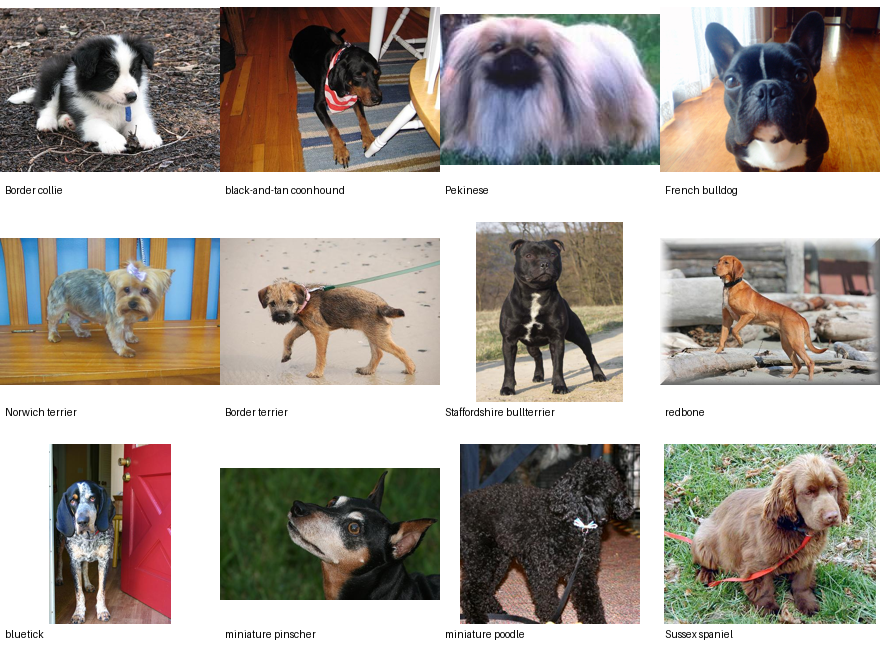

In [5]:
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display
import random

# Display 12 reproducibly sampled breed folders from the training dataset.
image_folders = sorted(p for p in IMAGE_ROOT.iterdir() if p.is_dir())
rng = random.Random(SEED)
sample_folders = rng.sample(image_folders, min(12, len(image_folders)))
thumb_width, thumb_height, label_height = 220, 180, 42
sheet = Image.new("RGB", (thumb_width * 4, (thumb_height + label_height) * 3), "white")
draw = ImageDraw.Draw(sheet)
for index, folder in enumerate(sample_folders):
    image_path = next(p for p in sorted(folder.iterdir()) if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    image = Image.open(image_path).convert("RGB")
    image.thumbnail((thumb_width, thumb_height))
    x = (index % 4) * thumb_width + (thumb_width - image.width) // 2
    y = (index // 4) * (thumb_height + label_height) + (thumb_height - image.height) // 2
    sheet.paste(image, (x, y))
    label = folder.name.split("-", 1)[-1].replace("_", " ")
    draw.text(((index % 4) * thumb_width + 5, (index // 4) * (thumb_height + label_height) + thumb_height + 4), label, fill="black")
print(f"Showing {len(sample_folders)} of {len(image_folders)} breeds; {len(full_train)} images total.")
display(sheet)


## Train, select, and evaluate the classifier

The ImageNet-pretrained ResNet-18 is trained on the official training partition. The validation subset selects the checkpoint; the official test partition is used once for final accuracy, macro-averaged scores, and confusion analysis.


In [6]:
import csv

model = models.resnet18(weights=ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
EPOCHS = 10

def run_epoch(loader, training: bool):
    model.train(training)
    total_loss = correct = total = 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

best_val_accuracy = 0.0
for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    val_loss, val_accuracy = run_epoch(valid_loader, training=False)
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {train_loss:.4f}, acc {train_accuracy:.3f} | val loss {val_loss:.4f}, acc {val_accuracy:.3f}")
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "image_size": IMAGE_SIZE,
            "val_accuracy": best_val_accuracy,
        }, "stanford_dogs_resnet18.pt")
print(f"Best validation accuracy: {best_val_accuracy:.3f}")

# Evaluate once on the untouched official test split using the best validation checkpoint.
checkpoint = torch.load("stanford_dogs_resnet18.pt", map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
confusion = np.zeros((num_classes, num_classes), dtype=np.int64)
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        predictions = model(images).argmax(dim=1)
        for actual, predicted in zip(labels.cpu().tolist(), predictions.cpu().tolist()):
            confusion[actual, predicted] += 1

tp = np.diag(confusion).astype(np.float64)
precision = tp / np.maximum(confusion.sum(axis=0), 1)
recall = tp / np.maximum(confusion.sum(axis=1), 1)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
test_accuracy = tp.sum() / confusion.sum()
print(f"Official test: accuracy={test_accuracy:.4f} | macro precision={precision.mean():.4f} | macro recall={recall.mean():.4f} | macro F1={f1.mean():.4f}")
np.savetxt("stanford_dogs_confusion_matrix.csv", confusion, delimiter=",", fmt="%d")
with open("stanford_dogs_per_breed_metrics.csv", "w", newline="") as metrics_file:
    writer = csv.writer(metrics_file)
    writer.writerow(["breed", "precision", "recall", "f1", "support"])
    for i, breed in enumerate(class_names):
        writer.writerow([breed, precision[i], recall[i], f1[i], int(confusion[i].sum())])



Epoch 01/10 | train loss 2.2504, acc 0.459 | val loss 1.6724, acc 0.538


Epoch 02/10 | train loss 1.2009, acc 0.660 | val loss 1.5436, acc 0.575


Epoch 03/10 | train loss 0.8883, acc 0.746 | val loss 1.5138, acc 0.579


Epoch 04/10 | train loss 0.6915, acc 0.797 | val loss 1.1948, acc 0.647


Epoch 05/10 | train loss 0.5236, acc 0.847 | val loss 1.1888, acc 0.655


...

Epoch 07/10 | train loss 0.3679, acc 0.889 | val loss 1.6069, acc 0.572


Epoch 08/10 | train loss 0.2948, acc 0.918 | val loss 1.3138, acc 0.648


Epoch 09/10 | train loss 0.2432, acc 0.930 | val loss 1.4733, acc 0.619


Epoch 10/10 | train loss 0.2288, acc 0.933 | val loss 1.5496, acc 0.597
Best validation accuracy: 0.655


Official test: accuracy=0.6608 | macro precision=0.6824 | macro recall=0.6557 | macro F1=0.6492


## Predict a breed from a photograph

The prediction helper uses the best validation checkpoint saved by the training cell.


In [7]:
from PIL import Image

checkpoint = torch.load("stanford_dogs_resnet18.pt", map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
class_names = checkpoint["class_names"]

def predict_breed(image_path: str, top_k: int = 5):
    image = Image.open(image_path).convert("RGB")
    batch = valid_transform(image).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        probabilities = model(batch).softmax(dim=1)[0]
    scores, indices = probabilities.topk(min(top_k, len(class_names)))
    return [(class_names[i], float(score)) for score, i in zip(scores.cpu(), indices.cpu())]

# Demo on a real Pembroke Welsh corgi photograph from Stanford Dogs.
DEMO_IMAGE = IMAGE_ROOT / "n02113023-Pembroke" / "n02113023_6548.jpg"
print("Image:", DEMO_IMAGE.name)
for breed, confidence in predict_breed(str(DEMO_IMAGE)):
    print(f"{breed}: {confidence:.1%}")


Image: n02113023_6548.jpg
n02113023-Pembroke: 59.9%
n02113186-Cardigan: 10.4%
n02110063-malamute: 5.0%
n02109961-Eskimo_dog: 3.8%
n02105855-Shetland_sheepdog: 3.7%


## Model artifact

Training writes `stanford_dogs_resnet18.pt` in the notebook working directory. The checkpoint contains model weights, breed names, image size, and validation accuracy.


## Test-set charts

Run this cell after the training and evaluation cell to create the per-breed recall and confusion-matrix figures used in the paper draft.


In [ ]:
%run plot_stanford_dogs_results.py
